✅ Zomato Dataset Loaded Successfully!
Total Rows: 9551 | Total Columns: 21

--- 1. FIRST 5 ROWS ---


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229



--- 2. MISSING VALUES CHECK ---
Cuisines    9
dtype: int64

--- 3. STATISTICAL SUMMARY ---


,Average Cost for two,Price range,Aggregate rating,Votes
count,9542.000000,9542.000000,9542.000000,9542.000000
mean,1200.326137,1.804968,2.665238,156.772060
std,16128.743876,0.905563,1.516588,430.203324
min,0.000000,1.000000,0.000000,0.000000
25%,250.000000,1.000000,2.500000,5.000000
50%,400.000000,2.000000,3.200000,31.000000
75%,700.000000,2.000000,3.700000,130.000000
max,800000.000000,4.000000,4.900000,10934.000000


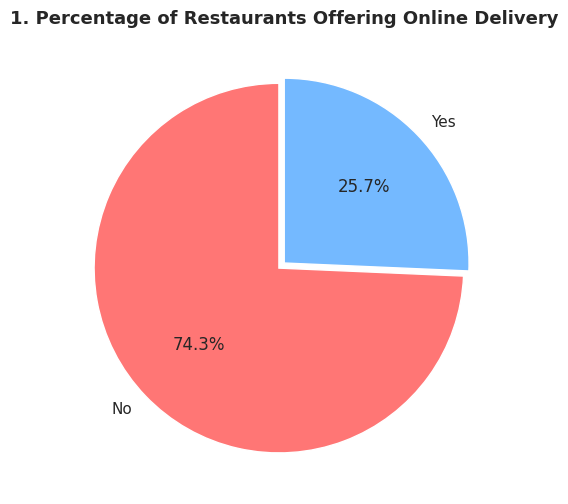

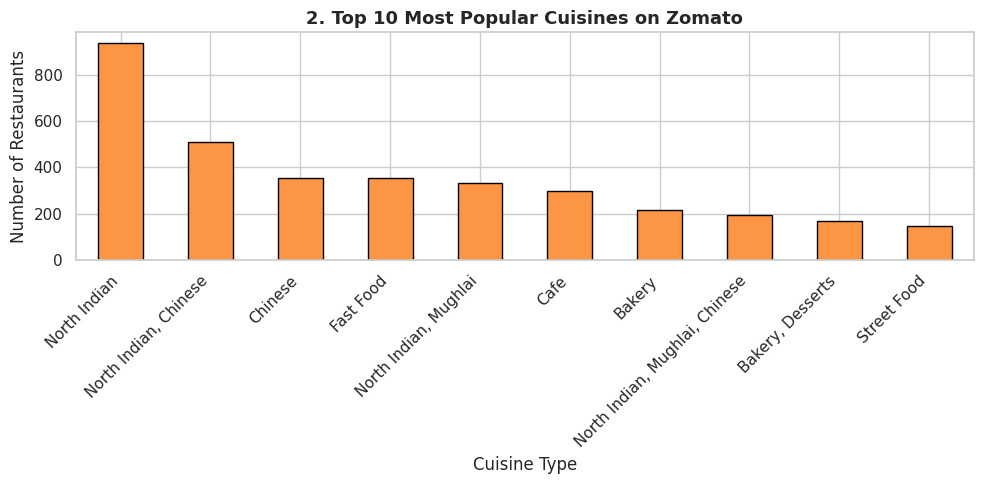

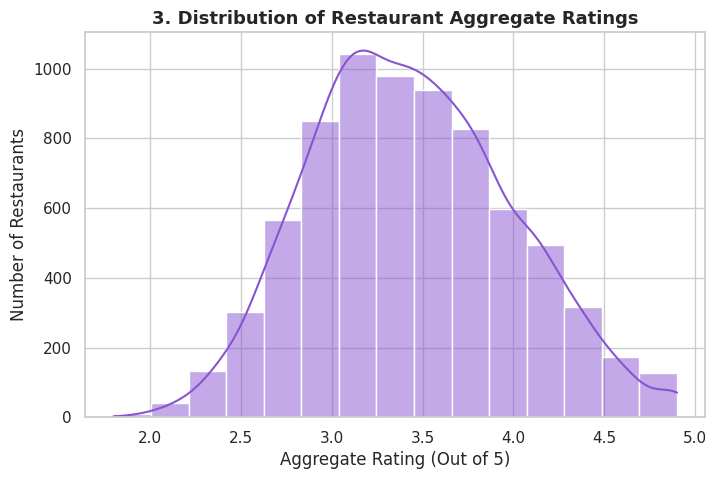

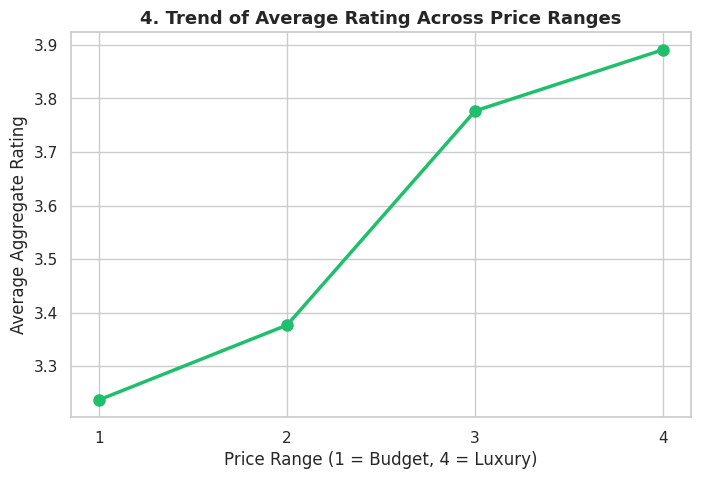

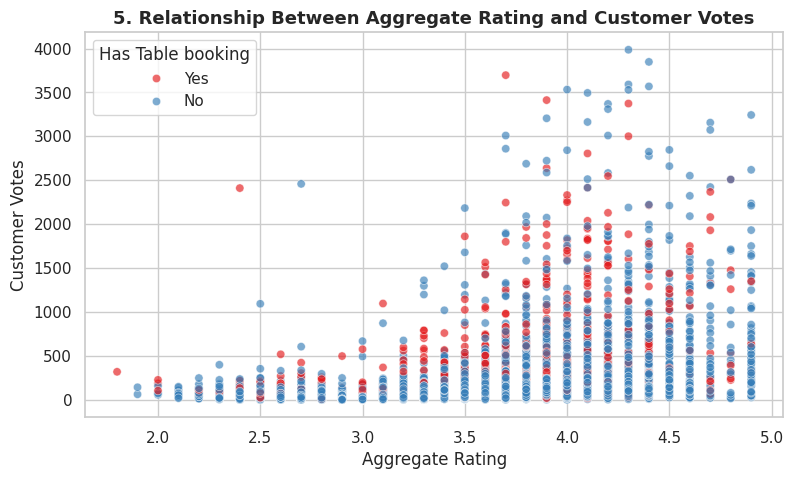

<Figure size 640x480 with 0 Axes>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD DATASET
df = pd.read_csv('zomato.csv', encoding='latin-1')
print("✅ Zomato Dataset Loaded Successfully!")
print(f"Total Rows: {df.shape[0]} | Total Columns: {df.shape[1]}\n")

# 2. EXPLORATORY DATA ANALYSIS (EDA)
print("--- 1. FIRST 5 ROWS ---")
display(df.head())

print("\n--- 2. MISSING VALUES CHECK ---")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Clean Missing Values
df.dropna(subset=['Cuisines'], inplace=True)

print("\n--- 3. STATISTICAL SUMMARY ---")
display(df[['Average Cost for two', 'Price range', 'Aggregate rating', 'Votes']].describe())

# ==========================================
# 3. DATA VISUALIZATIONS (5 MANDATORY CHARTS)
# ==========================================
sns.set_theme(style="whitegrid")

# CHART 1: PIE CHART - Online Delivery Distribution
plt.figure(figsize=(6, 6))
df['Has Online delivery'].value_counts().plot(
    kind='pie', autopct='%1.1f%%', startangle=90,
    colors=['#ff7675', '#74b9ff'], explode=[0.04, 0]
)
plt.title('1. Percentage of Restaurants Offering Online Delivery', fontsize=13, fontweight='bold')
plt.ylabel('')
plt.show()

# CHART 2: BAR CHART - Top 10 Cuisines on Zomato
plt.figure(figsize=(10, 5))
df['Cuisines'].value_counts().head(10).plot(kind='bar', color='#fd9644', edgecolor='black')
plt.title('2. Top 10 Most Popular Cuisines on Zomato', fontsize=13, fontweight='bold')
plt.xlabel('Cuisine Type')
plt.ylabel('Number of Restaurants')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# CHART 3: HISTOGRAM - Aggregate Rating Distribution
rated_df = df[df['Aggregate rating'] > 0]
plt.figure(figsize=(8, 5))
sns.histplot(rated_df['Aggregate rating'], bins=15, kde=True, color='#8854d0')
plt.title('3. Distribution of Restaurant Aggregate Ratings', fontsize=13, fontweight='bold')
plt.xlabel('Aggregate Rating (Out of 5)')
plt.ylabel('Number of Restaurants')
plt.show()

# CHART 4: LINE GRAPH - Average Rating Across Price Ranges
plt.figure(figsize=(8, 5))
price_trend = rated_df.groupby('Price range')['Aggregate rating'].mean()
price_trend.plot(kind='line', marker='o', color='#20bf6b', linewidth=2.5, markersize=8)
plt.title('4. Trend of Average Rating Across Price Ranges', fontsize=13, fontweight='bold')
plt.xlabel('Price Range (1 = Budget, 4 = Luxury)')
plt.ylabel('Average Aggregate Rating')
plt.xticks([1, 2, 3, 4])
plt.grid(True)
plt.show()

# CHART 5: SCATTER PLOT - Votes vs Aggregate Rating
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=rated_df[rated_df['Votes'] <= 4000],
    x='Aggregate rating', y='Votes', hue='Has Table booking',
    palette='Set1', alpha=0.65
)
plt.title('5. Relationship Between Aggregate Rating and Customer Votes', fontsize=13, fontweight='bold')
plt.xlabel('Aggregate Rating')
plt.ylabel('Customer Votes')
plt.show()
